# Milestone 2B — Review Stanford Cars overlap candidates

**Goal:** Inspect the cross-split image pairs generated by `prepare_stanford_cars.py`. Record a decision for **each pair**, then run the original script in `--review-only` mode to freeze the final manifest. No GPU is needed.

**How to decide:**

- `confirmed_duplicate`: the same original photograph (possibly compressed, resized, cropped, color-adjusted, or slightly modified) appears in different splits. Do **not** use this for merely the same model of car or two different photos of the same vehicle.
- `different_images`: two distinct photographs that only look similar (e.g., similarly framed cars or backgrounds).
- Undecided? Leave the decision blank and inspect at a larger size. Do not guess.

**Important:** dHash is only a *candidate finder*. `identical_bytes=true` is strong evidence of an exact duplicate. `dhash_distance` of 0–3 **does not prove** duplication; visually inspect.

This notebook edits only `splits/stanford/candidate_pair_review.csv` and does not alter raw images, the Pakistani dataset, or the frozen manifest.

In [1]:
from pathlib import Path
from collections import Counter
import csv
import os

import matplotlib.pyplot as plt
from PIL import Image


def find_root(start: Path) -> Path:
    # VS Code might launch the Jupyter kernel from the repo root or notebooks/.
    for directory in (start, *start.parents):
        if (directory / "splits/stanford/candidate_pair_review.csv").exists():
            return directory
    raise FileNotFoundError("Cannot find splits/stanford/candidate_pair_review.csv. Open this notebook within the project.")

ROOT = find_root(Path.cwd().resolve())
REVIEW_FILE = ROOT / "splits/stanford/candidate_pair_review.csv"


def load_pairs():
    with REVIEW_FILE.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

pairs = load_pairs()
print("Repository:", ROOT)
print("Candidate pairs:", len(pairs))
print("Already reviewed:", sum(bool(p["review_decision"].strip()) for p in pairs))
print("Pending:", sum(not p["review_decision"].strip() for p in pairs))

Repository: /Users/bata/Documents/vehicle-make-model-recognition
Candidate pairs: 39
Already reviewed: 0
Pending: 39


## 1. Inspect the photographs side by side

Pairs are indexed **0 to N−1** in the notebook. Review the photographs and the class labels. Each image is loaded from the original exported local file via its manifest path.

Call `show_pairs(start=0, count=4)` to see four pairs. Advance with `start=4`, `start=8`, and so on. For a bigger look at one pair, call `show_pairs(start=INDEX, count=1)`.

A false positive is common when two distinct car images have very similar silhouettes or backgrounds.

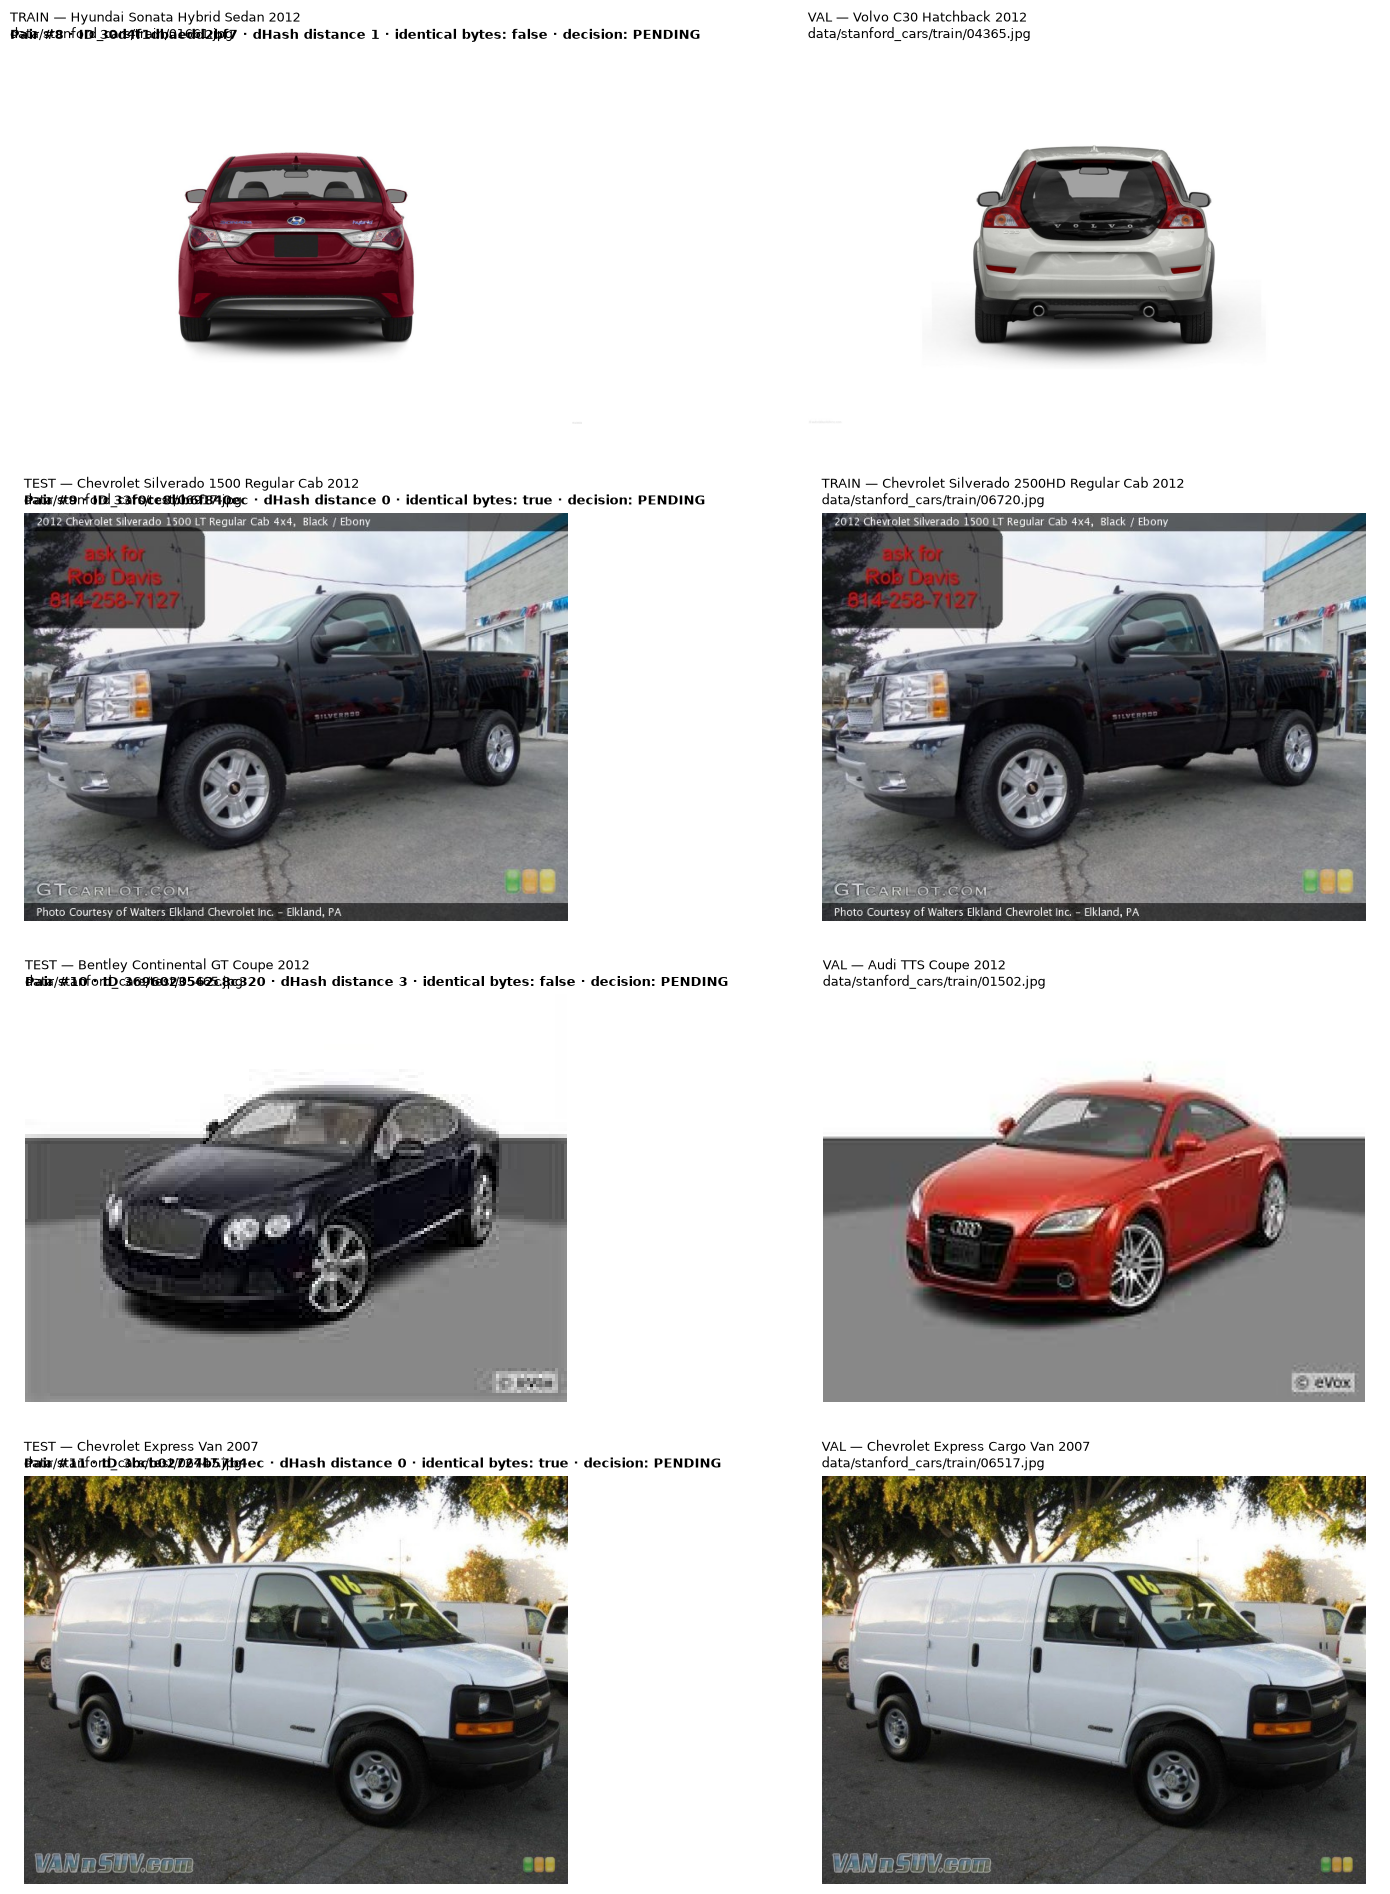

In [12]:
def show_pairs(start: int = 0, count: int = 4):
    pairs[:] = load_pairs()  # Refresh in case the CSV was changed elsewhere.
    if not (0 <= start < len(pairs)):
        raise IndexError(f"Start must be between 0 and {len(pairs)-1}")
    selected = list(enumerate(pairs[start:start + count], start=start))
    fig, axes = plt.subplots(len(selected), 2, figsize=(14, 4.8 * len(selected)), squeeze=False)
    for row_idx, (pair_index, row) in enumerate(selected):
        for side, col in (("a", 0), ("b", 1)):
            image_path = ROOT / row[f"path_{side}"]
            if not image_path.is_file():
                raise FileNotFoundError(image_path)
            with Image.open(image_path) as im:
                axes[row_idx, col].imshow(im.convert("RGB"))
            axes[row_idx, col].axis("off")
            axes[row_idx, col].set_title(
                f"{row[f'split_{side}'].upper()} — {row[f'class_{side}']}\n"
                f"{row[f'path_{side}']}",
                fontsize=9, loc="left", wrap=True
            )
        summary = (f"Pair #{pair_index} · ID {row['pair_id']} · "
                   f"dHash distance {row['dhash_distance']} · "
                   f"identical bytes: {row['identical_bytes']} · "
                   f"decision: {row['review_decision'] or 'PENDING'}")
        axes[row_idx, 0].text(0, 1.02, summary, transform=axes[row_idx, 0].transAxes,
                              fontsize=9, fontweight="bold")
    plt.tight_layout(h_pad=2.6)
    plt.show()

show_pairs(8, 4)

## 2. Save one review decision

After examining a pair, call:

```python
set_decision(0, "different_images")
# OR
set_decision(0, "confirmed_duplicate")
```

The index is the number displayed as **Pair #**. This function immediately saves your decision to the CSV, so it remains recorded if VS Code is closed. If unsure, do not set a decision yet. You can also correct an earlier decision by calling the function again.

**Do not execute the examples above without inspecting the actual images first.**

In [3]:
VALID_DECISIONS = {"different_images", "confirmed_duplicate"}


def set_decision(pair_index: int, decision: str):
    if decision not in VALID_DECISIONS:
        raise ValueError(f"Choose one of {sorted(VALID_DECISIONS)}")
    latest = load_pairs()
    if not (0 <= pair_index < len(latest)):
        raise IndexError(f"Pair index must be from 0 to {len(latest)-1}")
    target_id = latest[pair_index]["pair_id"]
    latest[pair_index]["review_decision"] = decision

    # Atomic replacement avoids a partially written CSV if execution is interrupted.
    temporary = REVIEW_FILE.with_name(REVIEW_FILE.name + ".tmp")
    with temporary.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=latest[0].keys())
        writer.writeheader()
        writer.writerows(latest)
    os.replace(temporary, REVIEW_FILE)
    pairs[:] = latest
    print(f"Saved pair #{pair_index} ({target_id}): {decision}")
    review_progress()


def review_progress():
    latest = load_pairs()
    counts = Counter(p["review_decision"].strip() or "PENDING" for p in latest)
    print("Progress:", dict(counts))
    pending = [i for i, p in enumerate(latest) if not p["review_decision"].strip()]
    print("Next pending index:", pending[0] if pending else "none — ready to finalize")

review_progress()

Progress: {'PENDING': 39}
Next pending index: 0


## 3. Continue through all candidates

For example, after reviewing the first group, run:

```python
show_pairs(4, 4)
```

Repeat with `8, 12, 16, ...` until all candidates have been visually inspected, recording each decision with `set_decision(index, "...")`. You may also edit the `review_decision` column directly in the CSV instead, but **do not edit it in two applications simultaneously**.

Afterward, run the progress cell below. It must report `PENDING: 0` before freezing.

In [4]:
review_progress()

Progress: {'PENDING': 39}
Next pending index: 0


## 4. Freeze Milestone 2B (terminal, not this notebook)

Return to the **repository root** in the VS Code terminal and run:

```bash
python src/prepare_stanford_cars.py --review-only
```

Expected status: `VERIFIED`, `unreviewed_pairs: 0`, and a new `splits/stanford/final_manifest.csv`. The official test count should remain **8,041**; train or validation counts can decrease if cross-split duplicates were confirmed and excluded. The final report must use *actual counts*, not the initial planned counts.

Then use `git status` and commit the **small metadata files** under `splits/stanford/`, plus this notebook and the preparation script. Do not commit the raw images under `data/`.

If a candidate appears genuinely ambiguous, leave it unresolved rather than inventing a decision. We can inspect it more closely.

In [13]:
for i in range(len(load_pairs())):
    set_decision(i, "confirmed_duplicate")

Saved pair #0 (0468f0997afac482): confirmed_duplicate
Progress: {'confirmed_duplicate': 1, 'PENDING': 38}
Next pending index: 1
Saved pair #1 (07c319becb829a76): confirmed_duplicate
Progress: {'confirmed_duplicate': 2, 'PENDING': 37}
Next pending index: 2
Saved pair #2 (07cabf0daa29df31): confirmed_duplicate
Progress: {'confirmed_duplicate': 3, 'PENDING': 36}
Next pending index: 3
Saved pair #3 (17da92a241e692be): confirmed_duplicate
Progress: {'confirmed_duplicate': 4, 'PENDING': 35}
Next pending index: 4
Saved pair #4 (17e68dc59a1af2e3): confirmed_duplicate
Progress: {'confirmed_duplicate': 5, 'PENDING': 34}
Next pending index: 5
Saved pair #5 (1d0777541ff1ccd3): confirmed_duplicate
Progress: {'confirmed_duplicate': 6, 'PENDING': 33}
Next pending index: 6
Saved pair #6 (202e4242f91710cc): confirmed_duplicate
Progress: {'confirmed_duplicate': 7, 'PENDING': 32}
Next pending index: 7
Saved pair #7 (2f9350d225e7dbb2): confirmed_duplicate
Progress: {'confirmed_duplicate': 8, 'PENDING': 31

In [14]:
review_progress()

Progress: {'confirmed_duplicate': 39}
Next pending index: none — ready to finalize
